# Recall at 50

**이 노트북에서 할 일**

1. 말뭉치 PDF 18건을 쪽마다 색인에 넣어 기준선 검색기를 만듭니다.
2. 개발 분할 15문항을 검색해 후보 목록에서 고유 문서를 세고 재현율을 계산합니다.
3. 자르는 자리를 50에서 5로 바꿔 질문 평균 재현율을 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열일곱 번입니다. 색인 한 벌에 한 번, 질문 검색에 열여섯 번입니다.
답을 쓰는 모델은 이 절에서 부르지 않습니다.

보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.
예상 비용은 열일곱 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 네 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

이 절은 파일을 쓰지 않습니다.

**강의와 실습 범위** — 강의 시간에는 2~7절을 설명합니다.
평가셋에서 개발 분할 고르기, 재현율 함수 만들기, 앞 챕터 기록으로 잴 수 있는 자리, 기준선 색인 만들기입니다.
8~11절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
01절 뒤에 패키지가 늘었으므로 이 명령을 다시 실행해야 합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

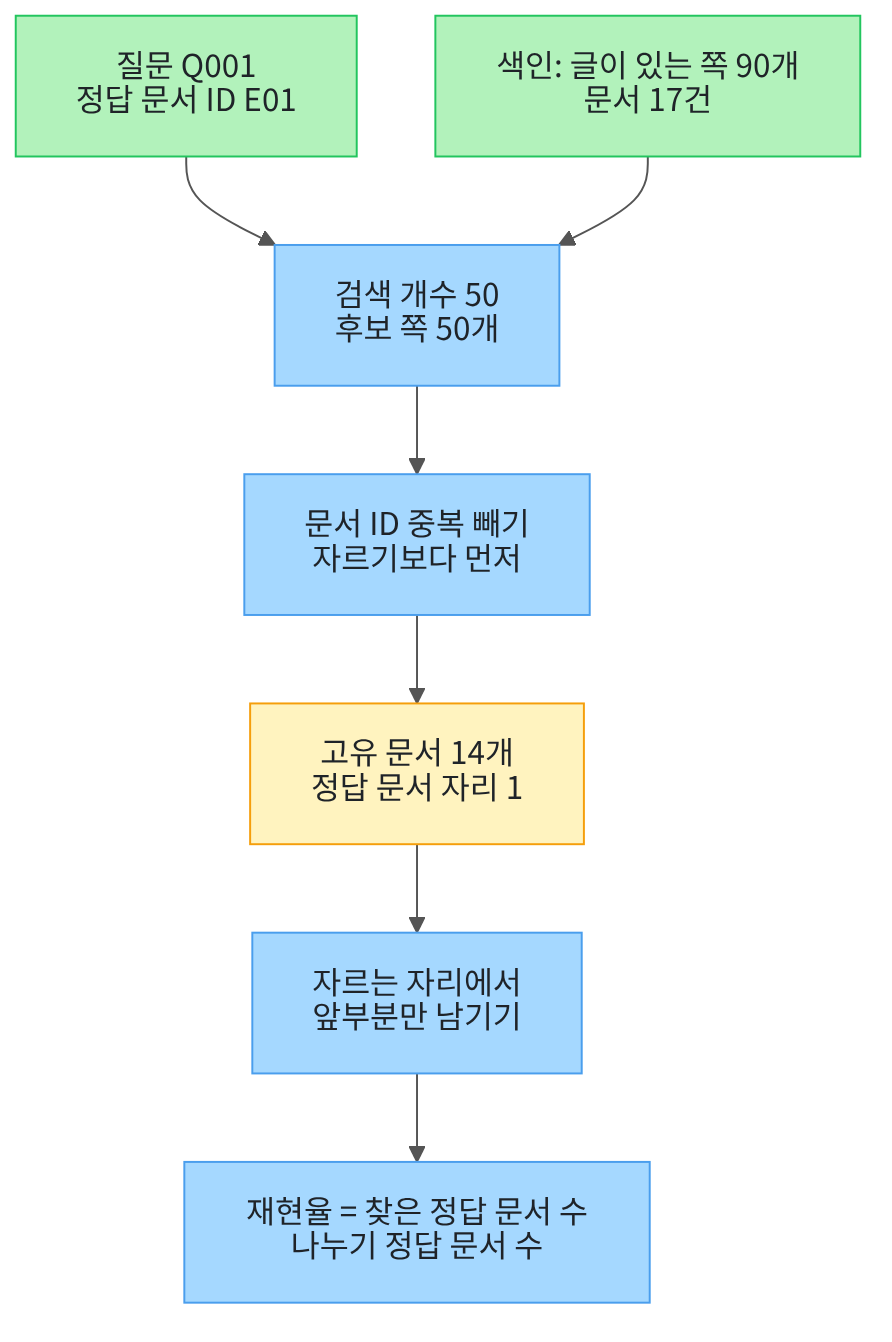

맨 위 초록 상자 두 개가 이 절의 입력입니다. 질문 하나와 쪽 90개를 담은 색인입니다.
가운데 파란 상자에서 후보 쪽 50개를 받아 문서 ID 중복을 먼저 빼고, 노란 상자에서 고유 문서를 셉니다.
맨 아래 두 파란 상자가 이 절이 새로 배우는 계산입니다. 앞부분만 남기고 정답 문서 비율을 냅니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절은 Python에 들어 있는 기능만 썼습니다. 이 절은 검색을 직접 하므로 패키지 다섯 개가 필요합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.1.1
langchain-core: 1.6.2
langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
넷째 줄 `numpy: 2.5.3`은 색인이 코사인 유사도를 계산할 때 쓰는 패키지입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
클래스 `InMemoryVectorStore`가 Ch 9 03절에서 쓴 색인이고 `OpenAIEmbeddings`가 임베딩을 부릅니다.
클래스 `Document`와 `PdfReader`는 Ch 9 01절과 Ch 10 01절에서 쪽을 읽을 때 쓴 이름입니다.

In [2]:
# 평가셋과 실행 기록 읽기·PDF 읽기·문서 객체·임베딩·색인에 쓸 이름을 불러옵니다
import json

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from pypdf import PdfReader

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 다음 셀에서 파일이 있는지 확인할 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 갈래 경로를 만듭니다.

In [5]:
# 이 절에서 읽을 파일 네 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다.
01절이 읽은 네 파일과 같고, 말뭉치 PDF 폴더가 하나 늘었습니다.

## 2. 평가셋에서 개발 분할 고르기

평가셋 30줄을 01절과 같은 방법으로 읽습니다.
그다음 칸 `split`이 `dev`인 줄만 남깁니다.
01절 b7에서 시험 분할 결과를 보고 설정을 다시 고르지 않기로 정했기 때문입니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))
print("첫 질문 번호:", dev_queries[0]["qid"])

평가셋 줄 수: 30
개발 분할 질문 수: 15
첫 질문 번호: Q001


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
셋째 줄 `첫 질문 번호: Q001`은 Ch 9 06절과 Ch 10 08절이 쓴 그 질문입니다.
01절 14절에서 본 것처럼 개발 분할은 앞부터 자르지 않고 15문항을 모두 씁니다.

## 3. 고유 문서 목록과 재현율 함수

01절 12절에서 만든 함수를 같은 코드로 가져옵니다.
검색 항목에서 처음 나온 문서 ID만 순서대로 남기는 함수입니다.

In [7]:
# 검색 항목에서 문서 ID를 순서대로 모으고 처음 나온 것만 남깁니다(01절 12절과 같은 코드)
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.

다음 셀이 이 절의 새 계산입니다.
고유 문서 목록을 자르는 자리에서 자르고, 정답 문서가 몇 개 들어왔는지 세어 비율을 냅니다.
정답 문서가 두 개인데 하나만 들어오면 값은 0.5가 됩니다.

In [8]:
# 고유 문서 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
인자 `cutoff`가 자르는 자리입니다. 목록 슬라이싱 `[:cutoff]`가 앞부분만 남깁니다.

다음 셀은 이 함수가 자르는 자리를 제대로 지키는지 통제 목록으로 확인합니다.
통제 목록은 검색 결과가 아니라 손으로 만든 문서 ID 51개입니다.
검색 품질이 아니라 계산의 경계를 보는 자리입니다.

In [9]:
# 손으로 만든 문서 ID 51개로 자르는 자리의 경계를 확인합니다
control_doc_ids = []
for number in range(1, 52):
    control_doc_ids.append("D" + str(number).zfill(2))

inside_score = recall_at(control_doc_ids, ["D50"], 50)
outside_score = recall_at(control_doc_ids, ["D51"], 50)
print("통제 목록의 문서 수:", len(control_doc_ids))
print("정답이 50번째일 때 재현율:", inside_score)
print("정답이 51번째일 때 재현율:", outside_score)
assert inside_score == 1.0
assert outside_score == 0.0

통제 목록의 문서 수: 51
정답이 50번째일 때 재현율: 1.0
정답이 51번째일 때 재현율: 0.0


**결과 읽기** — 출력 줄은 `통제 목록의 문서 수: 51`입니다.
둘째 줄 `정답이 50번째일 때 재현율: 1.0`과 셋째 줄 `정답이 51번째일 때 재현율: 0.0`이 경계입니다.
두 `assert`도 통과했습니다. 자르는 자리 50은 50번째까지 넣고 51번째는 뺍니다.

다음 셀은 질문마다 낸 점수를 하나의 값으로 모으는 함수입니다.
질문마다 같은 무게를 주어 평균합니다.

In [10]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
질문 수가 다른 묶음을 견줄 때도 이 방식이면 질문 하나의 무게가 같습니다.

## 4. 앞 챕터 기록으로 잴 수 있는 자리

01절은 Ch 9 06절 기록 1줄과 Ch 10 08절 기록 6줄을 읽었습니다.
같은 기록을 다시 읽어 줄마다 검색 항목이 몇 개 남았는지 셉니다.
이 수가 이 기록으로 자를 수 있는 가장 뒤 자리입니다.

In [11]:
# 01절에서 읽은 두 기록을 다시 읽어 줄마다 남은 검색 항목 수를 셉니다
log_paths = [ch09_log_path, ch10_log_path]
records = []
for log_path in log_paths:
    with open(log_path, encoding="utf-8") as log_file:
        log_lines = log_file.read().splitlines()
    for line in log_lines:
        records.append(json.loads(line))

logged_counts = []
for record in records:
    logged_counts.append(len(record["retrieved"]))
print("읽은 기록 줄 수:", len(records))
print("기록마다 남은 검색 항목 수:", logged_counts)

읽은 기록 줄 수: 7
기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]


**결과 읽기** — 첫 줄은 `읽은 기록 줄 수: 7`입니다.
둘째 줄은 `기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]`입니다.
Ch 9 기록은 검색 개수 2로, Ch 10 기록은 5로 실행한 결과입니다.
어느 줄도 항목이 50개에 이르지 않습니다.

다음 셀은 그 기록으로 낼 수 있는 값을 냅니다.
기록에 남은 항목 수만큼만 자른 재현율입니다.

In [12]:
# 앞 챕터 기록에서 기록 줄 수만큼만 자른 재현율을 냅니다
ch09_record = records[0]
ch10_record = records[1]
ch09_logged_k = len(ch09_record["retrieved"])
ch10_logged_k = len(ch10_record["retrieved"])
ch09_unique = unique_doc_ids(ch09_record["retrieved"])
ch10_unique = unique_doc_ids(ch10_record["retrieved"])
ch09_logged = recall_at(ch09_unique, ch09_record["gold_doc_ids"], ch09_logged_k)
ch10_logged = recall_at(ch10_unique, ch10_record["gold_doc_ids"], ch10_logged_k)
print("Ch 9 고유 문서:", ch09_unique)
print("Ch 9 기록 줄 수 자리의 재현율:", ch09_logged)
print("Ch 10 첫 줄 고유 문서:", ch10_unique)
print("Ch 10 첫 줄 기록 줄 수 자리의 재현율:", ch10_logged)

Ch 9 고유 문서: ['E01']
Ch 9 기록 줄 수 자리의 재현율: 1.0
Ch 10 첫 줄 고유 문서: ['E01', 'M04']
Ch 10 첫 줄 기록 줄 수 자리의 재현율: 1.0


**결과 읽기** — 첫 줄은 `Ch 9 고유 문서: ['E01']`이고 둘째 줄은 `Ch 9 기록 줄 수 자리의 재현율: 1.0`입니다.
넷째 줄 `Ch 10 첫 줄 기록 줄 수 자리의 재현율: 1.0`도 같은 값입니다.
두 기록 모두 정답 문서 `E01`이 고유 목록에 있었습니다.

실습 폴더 `evaluate.py`는 기록 줄 수가 50 이상일 때만 자르는 자리 50의 값을 냅니다.
그래서 이 두 기록의 그 칸은 `None`으로 남습니다.
질문도 Q001 하나뿐이라 질문 평균을 낼 수 없습니다.
그래서 다음 절부터 질문 15개에 후보 50개를 받는 기준선을 직접 만듭니다.

## 5. 기준선 색인 만들기

Ch 10 08절과 같은 방법으로 말뭉치 목록을 읽습니다.
네 갈래 가운데 `scanned`는 글자 층이 없는 스캔 변형이라 뺍니다.

In [13]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(Ch 10 08절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
01절 8절에서 말뭉치 목록의 문서 수 21을 이미 보았습니다.
Ch 9 06절과 Ch 10 08절 색인도 같은 18건을 썼습니다.

다음 셀은 Ch 9 01절에서 만든 로더 함수를 같은 코드로 가져옵니다.

In [14]:
# PDF 경로와 문서 이름을 받아 쪽마다 본문과 메타데이터를 담은 Document 목록을 반환합니다(Ch 10 08절과 같은 코드)
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

다음 셀은 이 함수로 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.

In [15]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))
print("첫 쪽의 메타데이터:", corpus_pages[0].metadata)

읽은 문서 수: 18
읽은 쪽 수: 93
첫 쪽의 메타데이터: {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'}


**결과 읽기** — 출력 첫 줄은 `읽은 문서 수: 18`이고 둘째 줄은 `읽은 쪽 수: 93`입니다.
셋째 줄 `첫 쪽의 메타데이터: {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'}`를 보세요.
Ch 9 06절과 Ch 10 08절도 같은 18건에서 93쪽을 읽었습니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.
Ch 10 02절에서 스캔 이미지만 있는 쪽은 글자 층이 비는 것을 확인했습니다.

In [16]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다.
문서로는 18건 가운데 17건만 색인에 들어갑니다. 이 수가 뒤에서 천장을 만듭니다.

빠진 세 쪽은 Ch 10 08절에서 글자 층이 비는 것을 확인한 `H05`의 쪽입니다.
스캔 이미지만 있어 쪽에서 글을 얻지 못했습니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [17]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-18에 이 임베딩 모델로 실행한 결과입니다.

## 6. 후보 목록 받기

검색 결과를 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다.
Ch 9 06절 기록의 검색 항목에서 문서 청크 이름과 점수를 뺀 모양입니다.
이 절 지표는 순위와 문서 ID만 쓰므로 점수를 받지 않습니다.

In [18]:
# 검색 결과를 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다
def make_candidate_list(hit_documents):
    candidates = []
    rank_number = 1
    for hit in hit_documents:
        candidates.append({"doc_id": hit.metadata["doc_id"], "page": hit.metadata["page"], "rank": rank_number})
        rank_number = rank_number + 1
    return candidates

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
순위는 1부터 차례로 붙입니다. Ch 9 06절 기록의 `rank` 칸과 같은 약속입니다.

다음 셀은 첫 질문 하나로 후보 목록의 모양을 봅니다.
실행 전에 예상해 봅니다. 후보는 쪽 단위라 50개가 오고, 문서 ID 중복을 빼면 그보다 적어질 것입니다.

In [19]:
# 첫 질문으로 후보 쪽 50개를 받아 고유 문서 목록과 정답 문서 자리를 봅니다
candidate_count = 50
first_query = dev_queries[0]
hit_documents = store.similarity_search(first_query["question"], k=candidate_count)
first_candidates = make_candidate_list(hit_documents)
first_unique = unique_doc_ids(first_candidates)
print("질문 번호:", first_query["qid"])
print("후보 수:", len(first_candidates))
print("고유 문서 수:", len(first_unique))
print("고유 문서 앞 다섯 개:", first_unique[:5])
print("정답 문서 ID:", first_query["gold_doc_ids"])

질문 번호: Q001
후보 수: 50
고유 문서 수: 14
고유 문서 앞 다섯 개: ['E01', 'M04', 'H03', 'M05', 'E04']
정답 문서 ID: ['E01']


**결과 읽기** — 둘째 줄은 `후보 수: 50`이고 셋째 줄은 `고유 문서 수: 14`입니다.
쪽 50개가 문서 14가지에서 왔다는 뜻입니다. 같은 문서의 쪽이 여러 개 올라왔습니다.
넷째 줄은 `고유 문서 앞 다섯 개: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
목록 첫 자리가 마지막 줄 `정답 문서 ID: ['E01']`과 같습니다.

## 7. 실행 1 — 자르는 자리 50

개발 분할 15문항을 차례로 검색합니다. 질문 하나에 임베딩 요청 한 번이 나갑니다.
반복문 안에서는 목록만 모으고 끝난 뒤에 한꺼번에 출력합니다.
실행 전에 예상합니다. 색인에 든 문서가 17건이라 고유 문서 수는 모두 50보다 작을 것입니다.

In [20]:
# 개발 분할 15문항을 차례로 검색해 질문마다 고유 문서 목록을 모읍니다
unique_by_qid = {}
for query in dev_queries:
    query_hits = store.similarity_search(query["question"], k=candidate_count)
    query_candidates = make_candidate_list(query_hits)
    unique_by_qid[query["qid"]] = unique_doc_ids(query_candidates)
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 고유 문서 수:", len(unique_by_qid["Q001"]))
print("질문 Q085의 고유 문서 수:", len(unique_by_qid["Q085"]))

검색한 질문 수: 15
질문 Q001의 고유 문서 수: 14
질문 Q085의 고유 문서 수: 15


**결과 읽기** — 첫 줄은 `검색한 질문 수: 15`입니다.
둘째 줄 `질문 Q001의 고유 문서 수: 14`는 6절에서 본 값과 같습니다.
셋째 줄은 `질문 Q085의 고유 문서 수: 15`입니다.
예상대로 두 값 모두 50보다 작습니다.

다음 셀은 질문마다 자르는 자리 50에서 재현율을 내고 질문 평균을 냅니다.

In [21]:
# 자르는 자리 50에서 질문마다 재현율을 내고 질문 평균을 냅니다
cutoff_wide = 50
wide_scores = []
print("질문 번호 | 고유 문서 수 | 재현율")
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    score = recall_at(doc_ids, query["gold_doc_ids"], cutoff_wide)
    wide_scores.append(score)
    print(query["qid"], "|", len(doc_ids), "|", score)
wide_mean = mean_score(wide_scores)
print("자르는 자리 50의 질문 평균 재현율:", wide_mean)

질문 번호 | 고유 문서 수 | 재현율
Q001 | 14 | 1.0
Q002 | 15 | 1.0
Q003 | 15 | 1.0
Q004 | 15 | 1.0
Q005 | 16 | 1.0
Q037 | 16 | 1.0
Q038 | 15 | 1.0
Q039 | 14 | 1.0
Q040 | 15 | 1.0
Q041 | 15 | 1.0
Q085 | 15 | 1.0
Q086 | 15 | 1.0
Q087 | 16 | 1.0
Q088 | 13 | 1.0
Q089 | 15 | 1.0
자르는 자리 50의 질문 평균 재현율: 1.0


**결과 읽기** — 라벨 줄 `질문 번호 | 고유 문서 수 | 재현율` 아래에 15줄이 있습니다.
첫 줄은 `Q001 | 14 | 1.0`이고 모든 줄의 재현율이 `1.0`입니다.
마지막 줄은 `자르는 자리 50의 질문 평균 재현율: 1.0`입니다.
정답 문서를 후보에서 놓친 질문이 이번 실행에는 없었습니다.

## 8. 실행 2 — 자르는 자리만 5로 바꾸기

같은 고유 문서 목록을 그대로 쓰고 자르는 자리만 5로 바꿉니다. 검색은 다시 하지 않습니다.
실행 전에 예상합니다. 정답 문서가 앞 5자리보다 뒤에 있던 질문은 0이 될 것입니다.

In [22]:
# 같은 고유 문서 목록에서 자르는 자리만 5로 바꿔 재현율을 다시 냅니다
cutoff_narrow = 5
narrow_scores = []
missed_qids = []
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    score = recall_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
    narrow_scores.append(score)
    if score < 1:
        missed_qids.append(query["qid"])
narrow_mean = mean_score(narrow_scores)
print("자르는 자리 5의 질문 평균 재현율:", narrow_mean)
print("정답 문서를 앞 5자리에서 놓친 질문:", missed_qids)

자르는 자리 5의 질문 평균 재현율: 0.867
정답 문서를 앞 5자리에서 놓친 질문: ['Q085', 'Q086']


**결과 읽기** — 첫 줄은 `자르는 자리 5의 질문 평균 재현율: 0.867`입니다.
둘째 줄은 `정답 문서를 앞 5자리에서 놓친 질문: ['Q085', 'Q086']`입니다.
15문항 가운데 두 문항에서 정답 문서가 앞 5자리 밖에 있었습니다.

앞 절에서 본 자리 50의 값 1.0보다 낮습니다.
후보 목록은 그대로이고 자르는 자리만 바뀌었습니다.

## 9. 놓친 질문의 정답 문서 자리

정답 문서가 몇 번째였는지 보면 왜 빠졌는지 읽을 수 있습니다.
01절 13절에서 만든 함수를 같은 코드로 가져옵니다.

In [23]:
# 고유 문서 목록에서 정답 문서 ID가 몇 번째 자리인지 찾습니다(01절 13절과 같은 코드)
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
찾지 못하면 `0`을 반환합니다.

다음 셀은 앞 5자리에서 놓친 두 질문의 정답 문서 자리와 두 자리의 재현율을 출력합니다.

In [24]:
# 앞 5자리에서 놓친 질문의 정답 문서 자리와 두 자리의 재현율을 함께 봅니다
print("질문 번호 | 정답 문서 ID | 정답 문서 자리 | 자리 50 | 자리 5")
for query in dev_queries:
    if query["qid"] in missed_qids:
        doc_ids = unique_by_qid[query["qid"]]
        gold_rank = find_gold_rank(doc_ids, query["gold_doc_ids"])
        wide_score = recall_at(doc_ids, query["gold_doc_ids"], cutoff_wide)
        narrow_score = recall_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
        print(query["qid"], "|", query["gold_doc_ids"], "|", gold_rank, "|", wide_score, "|", narrow_score)

질문 번호 | 정답 문서 ID | 정답 문서 자리 | 자리 50 | 자리 5
Q085 | ['H01'] | 10 | 1.0 | 0.0
Q086 | ['H01'] | 10 | 1.0 | 0.0


**결과 읽기** — 라벨 줄 아래 두 줄이 있습니다.
첫 줄은 `Q085 | ['H01'] | 10 | 1.0 | 0.0`이고 둘째 줄은 `Q086 | ['H01'] | 10 | 1.0 | 0.0`입니다.
두 질문 모두 정답 문서 `H01`이 고유 문서 목록의 10번째였습니다.
자리 50에서는 들어와 값이 1.0이고 자리 5에서는 빠져 0.0이 됩니다.

## 10. 자르는 자리 세 개 견주기

자르는 자리를 1과 5와 50으로 바꿔 질문 평균을 한 표로 봅니다.
검색은 다시 하지 않고 같은 고유 문서 목록을 씁니다.

In [25]:
# 자르는 자리를 1·5·50으로 바꿔 질문 평균을 한 번에 견줍니다
cutoff_values = [1, 5, 50]
print("자르는 자리 | 질문 평균 재현율")
for cutoff in cutoff_values:
    cutoff_scores = []
    for query in dev_queries:
        doc_ids = unique_by_qid[query["qid"]]
        cutoff_scores.append(recall_at(doc_ids, query["gold_doc_ids"], cutoff))
    print(cutoff, "|", mean_score(cutoff_scores))

자르는 자리 | 질문 평균 재현율
1 | 0.6
5 | 0.867
50 | 1.0


**결과 읽기** — 라벨 줄 아래 세 줄이 있습니다.
첫 줄은 `1 | 0.6`이고 둘째 줄은 `5 | 0.867`이며 셋째 줄은 `50 | 1.0`입니다.
자르는 자리를 줄이면 같은 검색 결과에서도 값이 내려갑니다.
자리 1은 1위 문서만 보는 값이라 15문항 가운데 아홉 문항에서만 정답 문서가 맞았습니다.

## 11. 정리

1. 후보 쪽 50개는 문서 ID 중복을 빼면 고유 문서 13~16개가 되었습니다.
2. 자르는 자리 50의 질문 평균 재현율은 1.0이고 자리 5에서는 0.867이었습니다.
3. 자리 5에서 빠진 Q085·Q086은 정답 문서가 고유 목록의 10번째였습니다.
4. 색인에 글이 있는 문서가 17건뿐이라 고유 문서 자리는 50을 채울 수 없습니다.
5. 자리 50의 값은 이 자료 크기에서 천장에 닿은 값입니다.

다음 03절에서는 앞 다섯 자리에 정답 문서가 얼마나 들어 있는지 Precision@5로 잽니다.